
# EmotionLens: Emotion Detector from Text

## Project Goal
Build a PyTorch Transformer model that predicts the dominant emotion in a short English text message.

## Dataset
- Source: dair-ai/emotion
- Configuration: split
- Text column: text
- Target column: label
- Required rows: 20,000
- Emotions: sadness, joy, love, anger, fear, surprise

## Team
- Team 13


In [ ]:

!pip -q install datasets pandas scikit-learn matplotlib seaborn


In [ ]:

import torch
import pandas as pd
import sklearn
import datasets

print("PyTorch version:", torch.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Datasets library loaded successfully!")
print("GPU available:", torch.cuda.is_available())


PyTorch version: 2.11.0+cpu
Pandas version: 2.2.3
Scikit-learn version: 1.6.1
Datasets library loaded successfully!
GPU available: False


In [ ]:

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json
import random
import numpy as np
import torch

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PROJECT_DIR = Path("/content/drive/MyDrive/Applied_AI/Team 13")
RAW_DIR = PROJECT_DIR / "dataset" / "raw"
PROCESSED_DIR = PROJECT_DIR / "dataset" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
RESULTS_DIR = PROJECT_DIR / "results"

# Create project folders if missing
for folder in [RAW_DIR, PROCESSED_DIR, ARTIFACTS_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project directory:", PROJECT_DIR)
print("PyTorch version:", torch.__version__)
print("Runtime device:", device)
print("All project folders created successfully!")


Mounted at /content/drive
Project directory: /content/drive/MyDrive/Applied_AI/Team 13
PyTorch version: 2.11.0+cpu
Runtime device: cpu
All project folders created successfully!


In [ ]:

from datasets import load_dataset

DATASET_ID = "dair-ai/emotion"
CONFIGURATION = "split"

# Download the required dataset
dataset = load_dataset(DATASET_ID, CONFIGURATION)

# Display dataset information
print("Dataset downloaded successfully!")
print("\nAvailable splits:", list(dataset.keys()))

for split_name, split_data in dataset.items():
    print(f"\n--- {split_name.upper()} ---")
    print("Number of rows:", len(split_data))
    print("Columns:", split_data.column_names)
    print("Features:", split_data.features)

    print("\nFirst 3 examples:")
    print(split_data.select(range(min(3, len(split_data)))).to_pandas())


README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset downloaded successfully!

Available splits: ['train', 'validation', 'test']

--- TRAIN ---
Number of rows: 16000
Columns: ['text', 'label']
Features: {'text': Value('string'), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}

First 3 examples:
                                                text  label
0                            i didnt feel humiliated      0
1  i can go from feeling so hopeless to so damned...      0
2   im grabbing a minute to post i feel greedy wrong      3

--- VALIDATION ---
Number of rows: 2000
Columns: ['text', 'label']
Features: {'text': Value('string'), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}

First 3 examples:
                                                text  label
0  im feeling quite sad and sorry for myself but ...      0
1  i feel like i am still looking at a blank canv...      0
2                     i feel like a faithful servant      2

--- TEST ---
Number of ro

In [ ]:

import json
import pandas as pd

# Check that all official splits exist
expected_counts = {
    "train": 16000,
    "validation": 2000,
    "test": 2000
}

assert set(dataset.keys()) == set(expected_counts.keys()), (
    f"Unexpected dataset splits: {list(dataset.keys())}"
)

# Check counts and required columns
for split_name, expected_count in expected_counts.items():
    split_data = dataset[split_name]

    assert len(split_data) == expected_count, (
        f"{split_name}: expected {expected_count}, got {len(split_data)}"
    )
    assert "text" in split_data.column_names
    assert "label" in split_data.column_names

    print(f"{split_name}: {len(split_data)} rows — OK")

# Check the six emotion labels
label_feature = dataset["train"].features["label"]
labels = label_feature.names

print("\nEmotion labels:")
for label_id, label_name in enumerate(labels):
    print(f"{label_id}: {label_name}")

assert len(labels) == 6, "Expected six emotion labels."

# Save original split copies without changing their columns
for split_name, split_data in dataset.items():
    output_path = RAW_DIR / f"source_{split_name}.parquet"
    split_data.to_parquet(str(output_path))
    print("Saved:", output_path.name)

# Save a record of the dataset source and official splits
manifest = {
    "dataset_id": "dair-ai/emotion",
    "configuration": "split",
    "text_column": "text",
    "target_column": "label",
    "official_split_counts": expected_counts,
    "total_rows": sum(expected_counts.values()),
    "label_names": labels,
    "random_seed": SEED
}

with open(RESULTS_DIR / "source_manifest.json", "w") as file:
    json.dump(manifest, file, indent=2)

print("\nTotal rows:", sum(len(dataset[s]) for s in dataset))
print("Dataset validation successful!")
print("Original split copies and manifest saved to Google Drive.")


train: 16000 rows — OK
validation: 2000 rows — OK
test: 2000 rows — OK

Emotion labels:
0: sadness
1: joy
2: love
3: anger
4: fear
5: surprise


Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Saved: source_train.parquet


Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Saved: source_validation.parquet


Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Saved: source_test.parquet

Total rows: 20000
Dataset validation successful!
Original split copies and manifest saved to Google Drive.


In [ ]:

import pandas as pd

# Convert each official split into a DataFrame
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

# Add the original split name for tracking
train_df["source_split"] = "train"
val_df["source_split"] = "validation"
test_df["source_split"] = "test"

# Combine copies for auditing only
all_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Check required fields
assert all_df["text"].notna().all(), "Some texts are missing."
assert all_df["label"].notna().all(), "Some labels are missing."

# Normalize text only for duplicate checking
all_df["text_for_audit"] = (
    all_df["text"]
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Count repeated normalized texts
duplicate_mask = all_df["text_for_audit"].duplicated(keep=False)
duplicate_rows = all_df[duplicate_mask].copy()

# Check whether any normalized text appears in multiple splits
split_counts = (
    all_df.groupby("text_for_audit")["source_split"]
    .nunique()
)
cross_split_texts = split_counts[split_counts > 1]

# Check texts that have conflicting labels
label_counts = (
    all_df.groupby("text_for_audit")["label"]
    .nunique()
)
conflicting_texts = label_counts[label_counts > 1]

print("Total rows:", len(all_df))
print("Repeated-text rows:", len(duplicate_rows))
print("Unique repeated texts:", duplicate_rows["text_for_audit"].nunique())
print("Texts occurring across multiple splits:", len(cross_split_texts))
print("Texts with conflicting labels:", len(conflicting_texts))

# Save audit reports
duplicate_rows.drop(columns=["text_for_audit"]).to_csv(
    RESULTS_DIR / "duplicate_text_audit.csv",
    index=False
)

cross_split_report = (
    all_df[all_df["text_for_audit"].isin(cross_split_texts.index)]
    [["text", "label", "source_split"]]
    .sort_values("text")
)
cross_split_report.to_csv(
    RESULTS_DIR / "cross_split_overlap_audit.csv",
    index=False
)

conflict_report = (
    all_df[all_df["text_for_audit"].isin(conflicting_texts.index)]
    [["text", "label", "source_split"]]
    .sort_values("text")
)
conflict_report.to_csv(
    RESULTS_DIR / "conflicting_labels_audit.csv",
    index=False
)

# Save processed copies, retaining official split assignments.
# The original raw files remain unchanged.
for split_name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    output_path = PROCESSED_DIR / f"{split_name}.parquet"
    frame.to_parquet(output_path, index=False)
    print(f"Saved {split_name}: {len(frame)} rows")

print("\nAudit reports saved in:", RESULTS_DIR)
print("Official splits preserved; no rows were deleted.")


Total rows: 20000
Repeated-text rows: 104
Unique repeated texts: 52
Texts occurring across multiple splits: 19
Texts with conflicting labels: 51
Saved train: 16000 rows
Saved validation: 2000 rows
Saved test: 2000 rows

Audit reports saved in: /content/drive/MyDrive/Applied_AI/Team 13/results
Official splits preserved; no rows were deleted.


In [ ]:

import re
import json
from collections import Counter

# Basic tokenizer that preserves contractions such as "don't"
def tokenize(text):
    return re.findall(r"\b\w+(?:'\w+)*\b|[^\w\s]", str(text).lower())

# Special tokens
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

# Build vocabulary using TRAINING TEXTS ONLY
word_counts = Counter()

for text in train_df["text"]:
    word_counts.update(tokenize(text))

# Reserve IDs 0 and 1 for special tokens
vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

# Sort by frequency, then alphabetically for reproducibility
for word, count in sorted(
    word_counts.items(),
    key=lambda item: (-item[1], item[0])
):
    if word not in vocab:
        vocab[word] = len(vocab)

# Save vocabulary permanently to Google Drive
vocab_path = ARTIFACTS_DIR / "vocabulary.json"

with open(vocab_path, "w", encoding="utf-8") as file:
    json.dump(vocab, file, ensure_ascii=False, indent=2)

# Save label names in the correct order
label_names = dataset["train"].features["label"].names
label_path = ARTIFACTS_DIR / "label_names.json"

with open(label_path, "w", encoding="utf-8") as file:
    json.dump(label_names, file, indent=2)

print("Vocabulary created successfully!")
print("Vocabulary size:", len(vocab))
print("Padding token ID:", vocab[PAD_TOKEN])
print("Unknown token ID:", vocab[UNK_TOKEN])
print("Emotion labels:", label_names)
print("Saved vocabulary to:", vocab_path)

# Example: convert one training message into token IDs
example_text = train_df["text"].iloc[0]
example_tokens = tokenize(example_text)
example_ids = [vocab.get(token, vocab[UNK_TOKEN])
               for token in example_tokens]

print("\nExample training message:", example_text)
print("Tokens:", example_tokens)
print("Token IDs:", example_ids)


Vocabulary created successfully!
Vocabulary size: 15214
Padding token ID: 0
Unknown token ID: 1
Emotion labels: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
Saved vocabulary to: /content/drive/MyDrive/Applied_AI/Team 13/artifacts/vocabulary.json

Example training message: i didnt feel humiliated
Tokens: ['i', 'didnt', 'feel', 'humiliated']
Token IDs: [2, 139, 3, 686]


In [ ]:

import json
import numpy as np

# Convert text into numerical token IDs
def encode_text(text):
    tokens = tokenize(text)
    return [vocab.get(token, vocab[UNK_TOKEN]) for token in tokens]

# Choose a sequence length using TRAINING data only.
# Keep at least 95% of training messages within this length,
# with a maximum of 128 tokens.
train_lengths = train_df["text"].apply(
    lambda text: len(tokenize(text))
)

MAX_LENGTH = min(
    128,
    max(1, int(np.ceil(train_lengths.quantile(0.95))))
)

print("Chosen maximum sequence length:", MAX_LENGTH)

# Encode each split without changing its official assignment
encoded_splits = {}

for split_name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    sequences = [
        encode_text(text)[:MAX_LENGTH]
        for text in frame["text"]
    ]

    encoded_splits[split_name] = {
        "input_ids": sequences,
        "labels": frame["label"].astype(int).tolist()
    }

    print(
        f"{split_name}: {len(sequences)} messages encoded"
    )

# Save preprocessing configuration
preprocessing_config = {
    "max_length": MAX_LENGTH,
    "padding_token": PAD_TOKEN,
    "padding_token_id": vocab[PAD_TOKEN],
    "unknown_token": UNK_TOKEN,
    "unknown_token_id": vocab[UNK_TOKEN],
    "tokenization": "lowercase regex; contractions preserved",
    "vocabulary_size": len(vocab),
    "labels": label_names,
    "vocabulary_fit_split": "train"
}

config_path = ARTIFACTS_DIR / "preprocessing_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(preprocessing_config, file, indent=2)

print("\nPreprocessing configuration saved:", config_path)

# Show one example
print("\nExample message:")
print(train_df["text"].iloc[0])
print("Encoded IDs:")
print(encoded_splits["train"]["input_ids"][0])
print("Correct label ID:")
print(encoded_splits["train"]["labels"][0])


Chosen maximum sequence length: 41
train: 16000 messages encoded
validation: 2000 messages encoded
test: 2000 messages encoded

Preprocessing configuration saved: /content/drive/MyDrive/Applied_AI/Team 13/artifacts/preprocessing_config.json

Example message:
i didnt feel humiliated
Encoded IDs:
[2, 139, 3, 686]
Correct label ID:
0


In [ ]:

import torch
from torch.utils.data import Dataset, DataLoader

# Use the same device selected earlier
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create a PyTorch Dataset
class EmotionDataset(Dataset):
    def __init__(self, split_data):
        self.input_ids = split_data["input_ids"]
        self.labels = split_data["labels"]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {
            "input_ids": self.input_ids[index],
            "label": self.labels[index]
        }

# Pad messages within each batch to the same length
def collate_batch(batch):
    batch_size = len(batch)
    batch_max_length = max(
        1, max(len(item["input_ids"]) for item in batch)
    )

    input_ids = torch.full(
        (batch_size, batch_max_length),
        fill_value=vocab[PAD_TOKEN],
        dtype=torch.long
    )

    labels = torch.tensor(
        [item["label"] for item in batch],
        dtype=torch.long
    )

    for i, item in enumerate(batch):
        ids = item["input_ids"]
        if ids:
            input_ids[i, :len(ids)] = torch.tensor(
                ids, dtype=torch.long
            )

    # 1 means a real token; 0 means padding
    attention_mask = (input_ids != vocab[PAD_TOKEN]).long()

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }

# Build separate datasets
train_dataset = EmotionDataset(encoded_splits["train"])
val_dataset = EmotionDataset(encoded_splits["validation"])
test_dataset = EmotionDataset(encoded_splits["test"])

# Build data loaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

# Inspect one training batch
batch = next(iter(train_loader))

print("Device:", device)
print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Test examples:", len(test_dataset))
print("\nInput IDs shape:", batch["input_ids"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)
print("Labels shape:", batch["labels"].shape)
print("First 5 labels:", batch["labels"][:5].tolist())
print("First message token IDs:", batch["input_ids"][0].tolist())
print("First message attention mask:", batch["attention_mask"][0].tolist())

assert batch["input_ids"].shape == batch["attention_mask"].shape
assert batch["input_ids"].shape[0] == BATCH_SIZE
assert batch["labels"].shape[0] == BATCH_SIZE

print("\nData loaders created successfully!")


Device: cpu
Training examples: 16000
Validation examples: 2000
Test examples: 2000

Input IDs shape: torch.Size([32, 41])
Attention mask shape: torch.Size([32, 41])
Labels shape: torch.Size([32])
First 5 labels: [5, 3, 1, 1, 0]
First message token IDs: [2, 112, 3, 14, 2, 105, 2330, 126, 108, 22, 459, 1905, 79, 7, 1023, 516, 1866, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
First message attention mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Data loaders created successfully!


In [ ]:

import torch
import torch.nn as nn

# Set model settings
VOCAB_SIZE = len(vocab)
NUM_LABELS = len(label_names)
D_MODEL = 128
NUM_HEADS = 4
NUM_LAYERS = 2
DROPOUT = 0.2

class EmotionTransformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        num_labels,
        max_length,
        d_model=128,
        num_heads=4,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        # Convert token IDs into vectors
        self.token_embedding = nn.Embedding(
            vocab_size, d_model, padding_idx=vocab[PAD_TOKEN]
        )

        # Give each token a position in the sentence
        self.position_embedding = nn.Embedding(
            max_length, d_model
        )

        # Learn relationships between tokens
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=d_model * 4,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.dropout = nn.Dropout(dropout)

        # Predict one of the six emotions
        self.classifier = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, num_labels)
        )

    def forward(self, input_ids, attention_mask):
        batch_size, sequence_length = input_ids.shape

        positions = torch.arange(
            sequence_length, device=input_ids.device
        ).unsqueeze(0).expand(batch_size, -1)

        # Token meaning + token position
        x = (
            self.token_embedding(input_ids)
            + self.position_embedding(positions)
        )

        # Ignore padding during attention
        padding_mask = attention_mask == 0

        x = self.transformer(
            x,
            src_key_padding_mask=padding_mask
        )

        # Masked mean pooling: average real tokens only
        mask = attention_mask.unsqueeze(-1).to(x.dtype)
        x = (x * mask).sum(dim=1)
        x = x / mask.sum(dim=1).clamp(min=1.0)

        # Six emotion scores (logits)
        logits = self.classifier(self.dropout(x))

        return logits


# Create the model
model = EmotionTransformer(
    vocab_size=VOCAB_SIZE,
    num_labels=NUM_LABELS,
    max_length=MAX_LENGTH,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(device)

print(model)
print("\nDevice:", device)
print("Vocabulary size:", VOCAB_SIZE)
print("Number of emotion classes:", NUM_LABELS)
print("Total model parameters:",
      sum(p.numel() for p in model.parameters()))


EmotionTransformer(
  (token_embedding): Embedding(15214, 128, padding_idx=0)
  (position_embedding): Embedding(41, 128)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=512, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=512, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): GELU(approximate='none')
   

In [ ]:

import torch.nn.functional as F

# Get one batch from the training data
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
targets = batch["labels"].to(device)

# Test the forward pass
model.train()
model.zero_grad(set_to_none=True)

logits = model(input_ids, attention_mask)
loss = F.cross_entropy(logits, targets)

print("Input shape:", input_ids.shape)
print("Logits shape:", logits.shape)
print("Loss:", loss.item())

# Confirm six emotion scores per message
assert logits.shape == (input_ids.shape[0], NUM_LABELS)
assert torch.isfinite(loss), "Loss is not finite!"

# Test backward pass and gradients
loss.backward()

gradients = [
    p.grad for p in model.parameters()
    if p.grad is not None
]

assert gradients, "No gradients were calculated!"
assert all(torch.isfinite(g).all().item() for g in gradients), (
    "A gradient contains non-finite values."
)

print("Forward pass: PASS")
print("Loss check: PASS")
print("Backward pass: PASS")
print("Gradient check: PASS")
print("\nTransformer model is ready for training!")


Input shape: torch.Size([32, 41])
Logits shape: torch.Size([32, 6])
Loss: 1.7869060039520264
Forward pass: PASS
Loss check: PASS
Backward pass: PASS
Gradient check: PASS

Transformer model is ready for training!


In [ ]:

import copy
import json
import time
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

# Training settings
EPOCHS = 8
LEARNING_RATE = 0.0003
WEIGHT_DECAY = 0.01
PATIENCE = 2

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)
criterion = nn.CrossEntropyLoss()

best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0
history = []

checkpoint_path = ARTIFACTS_DIR / "emotionlens_best_model.pth"
history_path = RESULTS_DIR / "training_history.json"

def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    total_examples = 0
    all_predictions = []
    all_targets = []

    progress = tqdm(loader, leave=False)

    for batch in progress:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        targets = batch["labels"].to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, targets)

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )
                optimizer.step()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_examples += batch_size

        predictions = logits.argmax(dim=1)
        all_predictions.extend(predictions.detach().cpu().tolist())
        all_targets.extend(targets.detach().cpu().tolist())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    average_loss = total_loss / total_examples
    macro_f1 = f1_score(
        all_targets,
        all_predictions,
        labels=list(range(NUM_LABELS)),
        average="macro",
        zero_division=0
    )

    return average_loss, macro_f1


# Train and validate
training_start = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    train_loss, train_macro_f1 = run_epoch(
        train_loader, training=True
    )
    val_loss, val_macro_f1 = run_epoch(
        val_loader, training=False
    )

    record = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "train_macro_f1": float(train_macro_f1),
        "val_loss": float(val_loss),
        "val_macro_f1": float(val_macro_f1)
    }
    history.append(record)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train macro F1: {train_macro_f1:.4f} | "
        f"Validation loss: {val_loss:.4f} | "
        f"Validation macro F1: {val_macro_f1:.4f} | "
        f"Time: {(time.time() - epoch_start):.1f}s"
    )

    # Save the checkpoint with the best validation macro F1
    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            copy.deepcopy(model.state_dict()),
            checkpoint_path
        )
        print("  Best checkpoint saved.")
    else:
        epochs_without_improvement += 1
        print(
            f"  No improvement: "
            f"{epochs_without_improvement}/{PATIENCE}"
        )

    # Save history after every epoch
    with open(history_path, "w", encoding="utf-8") as file:
        json.dump(history, file, indent=2)

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation macro F1 did not improve.")
        break

print("\nTraining finished.")
print("Best epoch:", best_epoch)
print("Best validation macro F1:", round(best_val_f1, 4))
print("Best checkpoint:", checkpoint_path)
print("Training history:", history_path)
print(f"Total training time: {(time.time() - training_start) / 60:.1f} minutes")


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Epoch 1/8 | Train loss: 1.5318 | Train macro F1: 0.1749 | Validation loss: 1.4317 | Validation macro F1: 0.2245 | Time: 55.6s
  Best checkpoint saved.


  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 7/8 | Train loss: 0.3281 | Train macro F1: 0.8640 | Validation loss: 0.6049 | Validation macro F1: 0.7978 | Time: 54.5s
  Best checkpoint saved.


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 8/8 | Train loss: 0.2743 | Train macro F1: 0.8825 | Validation loss: 0.5666 | Validation macro F1: 0.8131 | Time: 54.8s
  Best checkpoint saved.

Training finished.
Best epoch: 8
Best validation macro F1: 0.8131
Best checkpoint: /content/drive/MyDrive/Applied_AI/Team 13/artifacts/emotionlens_best_model.pth
Training history: /content/drive/MyDrive/Applied_AI/Team 13/results/training_history.json
Total training time: 7.3 minutes


In [ ]:

print("Best checkpoint exists:", checkpoint_path.exists())
print("Training history exists:", history_path.exists())
print("Epochs completed:", len(history))
print("Best epoch:", best_epoch)
print("Best validation macro F1:", round(best_val_f1, 4))


Best checkpoint exists: True
Training history exists: True
Epochs completed: 8
Best epoch: 8
Best validation macro F1: 0.8131


In [ ]:

import torch
import json
import matplotlib.pyplot as plt

# Load the best model selected using validation macro F1
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)
model.to(device)
model.eval()

# Load the recorded training history
with open(history_path, "r", encoding="utf-8") as file:
    saved_history = json.load(file)

print("Best model loaded successfully!")
print("Checkpoint exists:", checkpoint_path.exists())
print("Epochs recorded:", len(saved_history))
print("Best epoch:", best_epoch)
print("Best validation macro F1:", round(best_val_f1, 4))


Best model loaded successfully!
Checkpoint exists: True
Epochs recorded: 8
Best epoch: 8
Best validation macro F1: 0.8131


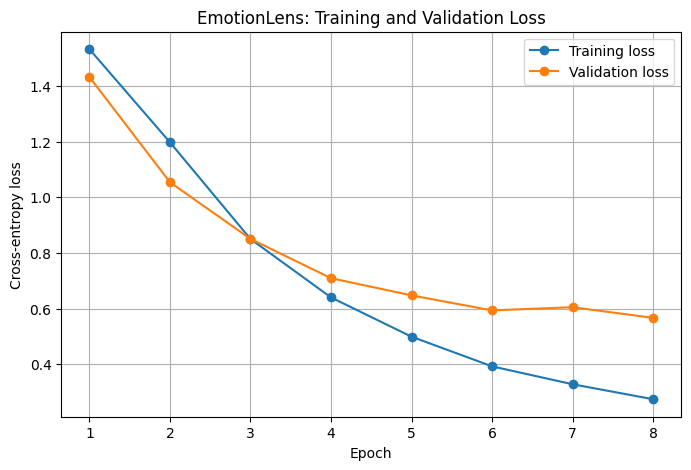

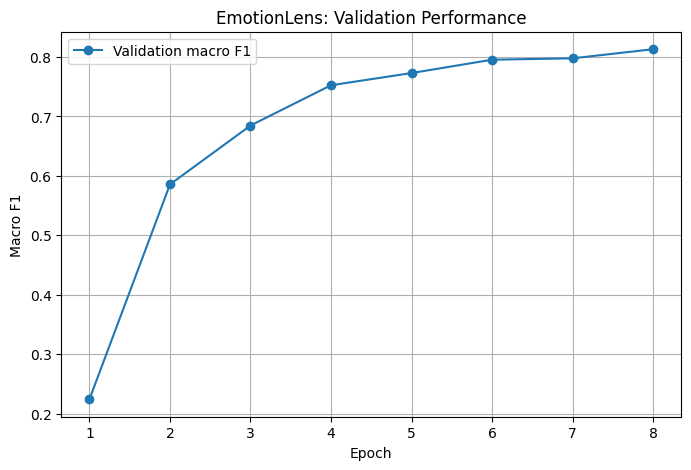

In [ ]:

epochs = [row["epoch"] for row in saved_history]
train_losses = [row["train_loss"] for row in saved_history]
val_losses = [row["val_loss"] for row in saved_history]
val_f1_scores = [row["val_macro_f1"] for row in saved_history]

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker="o", label="Training loss")
plt.plot(epochs, val_losses, marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("EmotionLens: Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, val_f1_scores, marker="o", label="Validation macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("EmotionLens: Validation Performance")
plt.legend()
plt.grid(True)
plt.show()


TEST ACCURACY: 0.8205

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

     sadness     0.8345    0.8417    0.8380       581
         joy     0.8340    0.8676    0.8505       695
        love     0.7163    0.6352    0.6733       159
       anger     0.8523    0.8182    0.8349       275
        fear     0.8447    0.7768    0.8093       224
    surprise     0.6125    0.7424    0.6712        66

    accuracy                         0.8205      2000
   macro avg     0.7824    0.7803    0.7795      2000
weighted avg     0.8212    0.8205    0.8201      2000



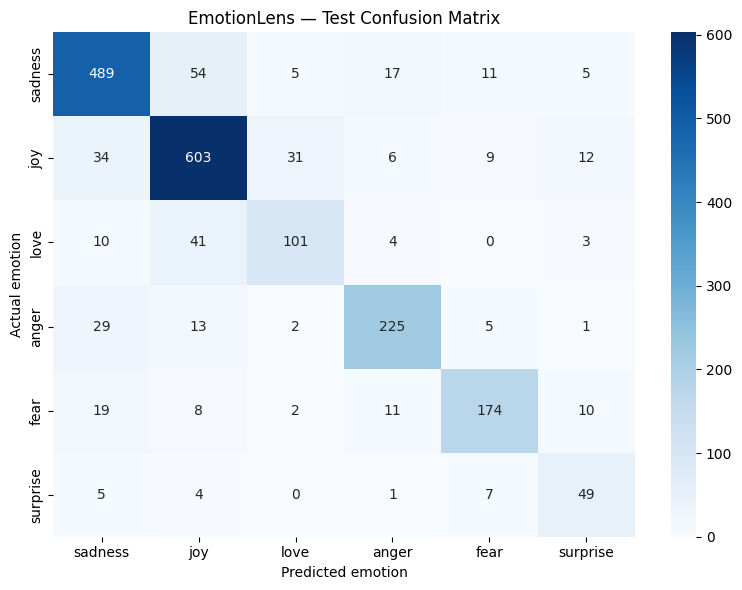


Test class metrics saved.
Overall accuracy: 0.8205
Macro F1: 0.7795
Weighted F1: 0.8201


In [ ]:

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

# Restore the best checkpoint selected on validation data
state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)
model.load_state_dict(state_dict)
model.to(device)
model.eval()

all_predictions = []
all_targets = []
all_confidences = []

# Evaluate the test set only now
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        targets = batch["labels"].to(device)

        logits = model(input_ids, attention_mask)
        probabilities = torch.softmax(logits, dim=1)

        predictions = logits.argmax(dim=1)
        confidences = probabilities.max(dim=1).values

        all_predictions.extend(predictions.cpu().tolist())
        all_targets.extend(targets.cpu().tolist())
        all_confidences.extend(confidences.cpu().tolist())

# Calculate final metrics
accuracy = accuracy_score(all_targets, all_predictions)

print("TEST ACCURACY:", round(accuracy, 4))
print("\nCLASSIFICATION REPORT:")
report = classification_report(
    all_targets,
    all_predictions,
    labels=list(range(NUM_LABELS)),
    target_names=label_names,
    digits=4,
    zero_division=0
)
print(report)

# Confusion matrix
cm = confusion_matrix(
    all_targets,
    all_predictions,
    labels=list(range(NUM_LABELS))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names
)
plt.xlabel("Predicted emotion")
plt.ylabel("Actual emotion")
plt.title("EmotionLens — Test Confusion Matrix")
plt.tight_layout()
plt.show()

# Save test results
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    all_targets,
    all_predictions,
    labels=list(range(NUM_LABELS)),
    zero_division=0
)

test_results = pd.DataFrame({
    "emotion": label_names,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "support": support
})

test_results.to_csv(
    RESULTS_DIR / "test_class_metrics.csv",
    index=False
)

print("\nTest class metrics saved.")
print("Overall accuracy:", round(accuracy, 4))
print("Macro F1:", round(
    f1_score(all_targets, all_predictions, average="macro"), 4
))
print("Weighted F1:", round(
    f1_score(all_targets, all_predictions, average="weighted"), 4
))


In [ ]:

# Collect incorrect predictions from the final test evaluation
error_rows = []

test_texts = test_df["text"].astype(str).tolist()

for i, (true_id, pred_id, confidence) in enumerate(
    zip(all_targets, all_predictions, all_confidences)
):
    if true_id != pred_id:
        error_rows.append({
            "text": test_texts[i],
            "actual_emotion": label_names[true_id],
            "predicted_emotion": label_names[pred_id],
            "prediction_confidence": round(float(confidence), 4)
        })

errors_df = pd.DataFrame(error_rows)

# Save all test mistakes for analysis
errors_path = RESULTS_DIR / "incorrect_test_predictions.csv"
errors_df.to_csv(errors_path, index=False)

print("Total incorrect predictions:", len(errors_df))
print("\nFirst 5 incorrect predictions:")
display(errors_df.head(5))

print("\nSaved to:", errors_path)


Total incorrect predictions: 359

First 5 incorrect predictions:


,text,actual_emotion,predicted_emotion,prediction_confidence
0,i felt anger when at the end of a telephone call,anger,sadness,0.8983
1,i jest i feel grumpy tired and pre menstrual w...,anger,love,0.6123
2,i don t feel particularly agitated,fear,anger,0.9772
3,i pay attention it deepens into a feeling of b...,fear,sadness,0.7652
4,i find myself in the odd position of feeling s...,love,joy,0.5279



Saved to: /content/drive/MyDrive/Applied_AI/Team 13/results/incorrect_test_predictions.csv


In [ ]:

import torch
import pandas as pd

# Restore the trained model
state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)
model.load_state_dict(state_dict)
model.to(device)
model.eval()

def predict_emotion(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please enter a non-empty text message.")

    tokens = tokenize(text)[:MAX_LENGTH]
    token_ids = [
        vocab.get(token, vocab[UNK_TOKEN])
        for token in tokens
    ]

    if not token_ids:
        token_ids = [vocab[UNK_TOKEN]]

    input_ids = torch.tensor(
        [token_ids], dtype=torch.long, device=device
    )
    attention_mask = torch.ones_like(input_ids)

    with torch.no_grad():
        logits = model(input_ids, attention_mask)
        probabilities = torch.softmax(logits, dim=1)[0]

    predicted_id = int(probabilities.argmax().item())

    return {
        "text": text,
        "predicted_emotion": label_names[predicted_id],
        "confidence": round(
            float(probabilities[predicted_id].item()), 4
        )
    }

print("EmotionLens prediction function is ready!")


EmotionLens prediction function is ready!


In [ ]:

sample_messages = [
    "I am so happy today",
    "I feel very sad and lonely",
    "I love spending time with my family",
    "I am afraid of what might happen",
    "I am angry about this situation",
    "Wow, I did not expect that surprise"
]

results = [predict_emotion(text) for text in sample_messages]

display(pd.DataFrame(results))


,text,predicted_emotion,confidence
0,I am so happy today,joy,0.9992
1,I feel very sad and lonely,sadness,0.9981
2,I love spending time with my family,joy,0.9609
3,I am afraid of what might happen,sadness,0.9462
4,I am angry about this situation,anger,0.9977
5,"Wow, I did not expect that surprise",anger,0.5499


In [ ]:

import json
from datetime import datetime, timezone
from sklearn.metrics import f1_score

final_config = {
    "project": "EmotionLens: Emotion Detector from Text",
    "team": "Team 13",
    "framework": "PyTorch",
    "architecture": "Transformer Encoder",
    "vocabulary_size": len(vocab),
    "num_labels": NUM_LABELS,
    "label_names": label_names,
    "max_length": MAX_LENGTH,
    "d_model": D_MODEL,
    "num_heads": NUM_HEADS,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "seed": SEED,
    "best_epoch": best_epoch,
    "best_validation_macro_f1": float(best_val_f1),
    "test_accuracy": float(accuracy),
    "test_macro_f1": float(
        f1_score(all_targets, all_predictions, average="macro")
    ),
    "test_weighted_f1": float(
        f1_score(all_targets, all_predictions, average="weighted")
    ),
    "created_at_utc": datetime.now(timezone.utc).isoformat()
}

config_file = ARTIFACTS_DIR / "emotionlens_config.json"

with open(config_file, "w", encoding="utf-8") as file:
    json.dump(final_config, file, indent=2)

print("Final configuration saved:", config_file)
print("Checkpoint exists:", checkpoint_path.exists())
print("Vocabulary exists:", vocab_path.exists())
print("Labels exist:", label_path.exists())
print("Configuration exists:", config_file.exists())


Final configuration saved: /content/drive/MyDrive/Applied_AI/Team 13/artifacts/emotionlens_config.json
Checkpoint exists: True
Vocabulary exists: True
Labels exist: True
Configuration exists: True


In [ ]:

print("PROJECT FILE CHECK")

for folder in [RAW_DIR, PROCESSED_DIR, ARTIFACTS_DIR, RESULTS_DIR]:
    print(f"\n{folder.name}/")
    for path in sorted(folder.iterdir()):
        if path.is_file():
            print(f"  {path.name} — {path.stat().st_size:,} bytes")


PROJECT FILE CHECK

raw/
  source_test.parquet — 125,747 bytes
  source_train.parquet — 991,381 bytes
  source_validation.parquet — 123,525 bytes

processed/
  test.parquet — 126,609 bytes
  train.parquet — 992,366 bytes
  validation.parquet — 124,418 bytes

artifacts/
  emotionlens_best_model.pth — 9,477,669 bytes
  emotionlens_config.json — 635 bytes
  label_names.json — 69 bytes
  preprocessing_config.json — 349 bytes
  vocabulary.json — 293,763 bytes

results/
  conflicting_labels_audit.csv — 9,690 bytes
  cross_split_overlap_audit.csv — 3,792 bytes
  duplicate_text_audit.csv — 9,832 bytes
  incorrect_test_predictions.csv — 50,222 bytes
  source_manifest.json — 359 bytes
  test_class_metrics.csv — 432 bytes
  training_history.json — 1,443 bytes


In [ ]:

required_files = [
    checkpoint_path,
    vocab_path,
    label_path,
    config_file,
    summary_path,
    report_path,
    history_path,
    RESULTS_DIR / "test_class_metrics.csv",
    RESULTS_DIR / "incorrect_test_predictions.csv"
]

print("FINAL FILE CHECK\n")

all_present = True

for path in required_files:
    exists = path.exists()
    print(("PASS" if exists else "MISSING"), "-", path.name)
    all_present = all_present and exists

print("\nAll required files present:", all_present)


FINAL FILE CHECK

PASS - emotionlens_best_model.pth
PASS - vocabulary.json
PASS - label_names.json
PASS - emotionlens_config.json
PASS - final_project_summary.json
PASS - final_classification_report.txt
PASS - training_history.json
PASS - test_class_metrics.csv
PASS - incorrect_test_predictions.csv

All required files present: True
